# Low-T stiffness networks


In [1]:
%matplotlib inline
from pathlib import Path
import sys
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

ROOT=Path.cwd().resolve()
while not (ROOT/'notebooks').exists(): ROOT=ROOT.parent
if str(ROOT/'src') not in sys.path: sys.path.insert(0,str(ROOT/'src'))
GRAPH_UTILS_SITE=Path('/rg/mendels_prj/alexander.z/DL-course-project/.venv/lib/python3.10/site-packages')
if str(GRAPH_UTILS_SITE) not in sys.path: sys.path.append(str(GRAPH_UTILS_SITE))
import networkx as nx
from graph_utils import draw_graph, remove_periodic_edges
from lss.plotting import apply_editorial_style, PAPER_COLORS, style_axes
PLOT_THEME='light'
apply_editorial_style(PLOT_THEME)

BASE=ROOT/'notebooks/results/all4_coverage_1000'
RUNS={'1 per source':BASE/'all4_one_each_retry_v5_validation30',
      '20 per source':BASE/'all4_twenty_each_retry_v5_validation30'}
SOURCES=['stiffness_low']
PLOT_SOURCES=['node_low','stiffness_low']
LABELS={'node_low':'node optimized','stiffness_low':'stiffness optimized'}
data={}
for name,path in RUNS.items():
    required=[path/'test/latents.csv',path/'test/per_network.csv']
    missing=[str(p) for p in required if not p.exists()]
    if missing: raise FileNotFoundError('Missing frozen artifacts:\n'+'\n'.join(missing))
    data[name]={'latents':pd.read_csv(required[0]),'network':pd.read_csv(required[1])}
print('Loaded identical held-out stiffness-low IDs 40–119: 80 trajectories × 200 frames for each frozen model.')


Loaded identical held-out stiffness-low IDs 40–119: 80 trajectories × 200 frames for each frozen model.


## Direct z0/z1 descriptors


In [2]:
descriptor_rows=[]; frame_parts=[]; geometry_rows=[]
for training,item in data.items():
    response=(item['network'].query("mode=='ae_reconstruction' and source=='stiffness_low' and frame==199")
              [['source','trajectory_id','true_p_ratio']].rename(columns={'true_p_ratio':'final_p_ratio'}))
    for source in SOURCES:
        frames=item['latents'].query('source==@source').sort_values(['trajectory_id','frame']).copy()
        frames['training']=training; frame_parts.append(frames)
        initial=frames.query('frame==0')[['trajectory_id','z0','z1']]
        values=initial[['z0','z1']].to_numpy(); singular=np.linalg.svd(values-values.mean(0),compute_uv=False); eig=singular**2
        zcorr=abs(initial.z0.corr(initial.z1))
        geometry_rows.append({'training':training,'source':LABELS[source],
            '|corr(initial z0,z1)|':zcorr,'shared initial variation r²':zcorr**2,
            'initial effective dimension':eig.sum()**2/np.square(eig).sum(),
            'networks':'80/80'})
        p=response.query('source==@source').set_index('trajectory_id').final_p_ratio
        for ident,g in frames.groupby('trajectory_id'):
            g=g.sort_values('frame')
            descriptor_rows.append({'training':training,'source':source,'trajectory_id':ident,
                'final_p_ratio':p.loc[ident],'initial z0':g.z0.iloc[0],'initial z1':g.z1.iloc[0]})
descriptors=pd.DataFrame(descriptor_rows); frame_df=pd.concat(frame_parts,ignore_index=True); geometry=pd.DataFrame(geometry_rows)
display(geometry.round(3))


,training,source,"|corr(initial z0,z1)|",shared initial variation r²,initial effective dimension,networks
0,1 per source,stiffness optimized,0.999,0.999,1.000,80/80
1,20 per source,stiffness optimized,0.529,0.280,1.405,80/80


## Initial latent and p-ratio


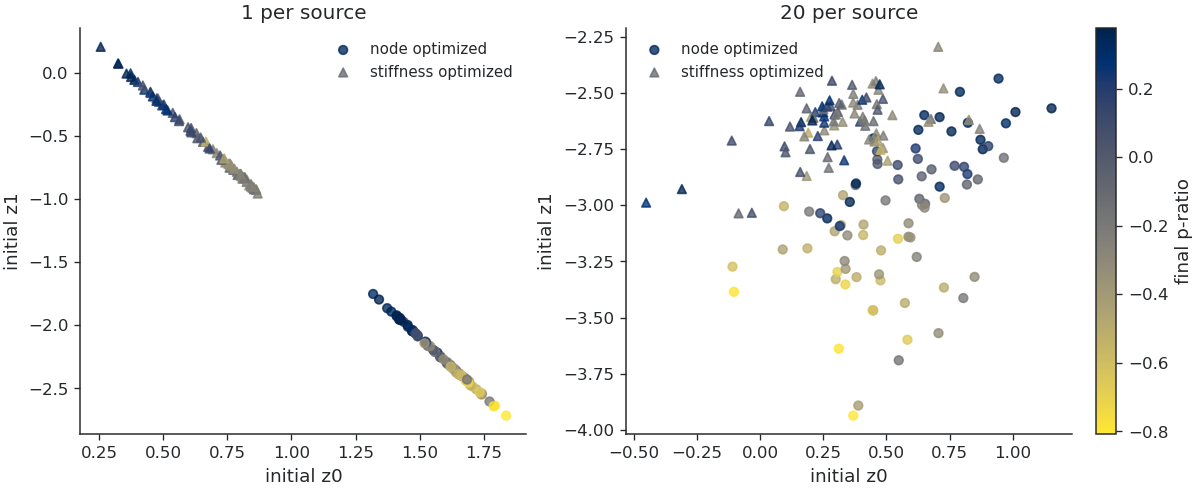

In [3]:
initial_parts=[]
for training,item in data.items():
    latent=item['latents'].query("frame==0 and source in @PLOT_SOURCES") [['source','trajectory_id','z0','z1']]
    truth=(item['network'].query("mode=='ae_reconstruction' and frame==199 and source in @PLOT_SOURCES")
           [['source','trajectory_id','true_p_ratio']].rename(columns={'true_p_ratio':'final_p_ratio'}))
    values=latent.merge(truth,on=['source','trajectory_id'],validate='one_to_one')
    values['training']=training; initial_parts.append(values)
initial_plot=pd.concat(initial_parts,ignore_index=True)
norm=plt.Normalize(initial_plot.final_p_ratio.min(),initial_plot.final_p_ratio.max())
markers={'node_low':'o','stiffness_low':'^'}
fig,axes=plt.subplots(1,2,figsize=(10,4.1),constrained_layout=True)
for ax,training in zip(axes,RUNS):
    for source in PLOT_SOURCES:
        g=initial_plot.query('training==@training and source==@source')
        ax.scatter(g['z0'],g['z1'],c=g.final_p_ratio,cmap='cividis_r',norm=norm,
                   marker=markers[source],s=27,alpha=.78,label=LABELS[source])
    ax.set_title(training); style_axes(ax,xlabel='initial z0',ylabel='initial z1',legend=True)
fig.colorbar(plt.cm.ScalarMappable(norm=norm,cmap='cividis_r'),ax=axes,label='final p-ratio',fraction=.026,pad=.02)
plt.show()


## Static reference descriptors


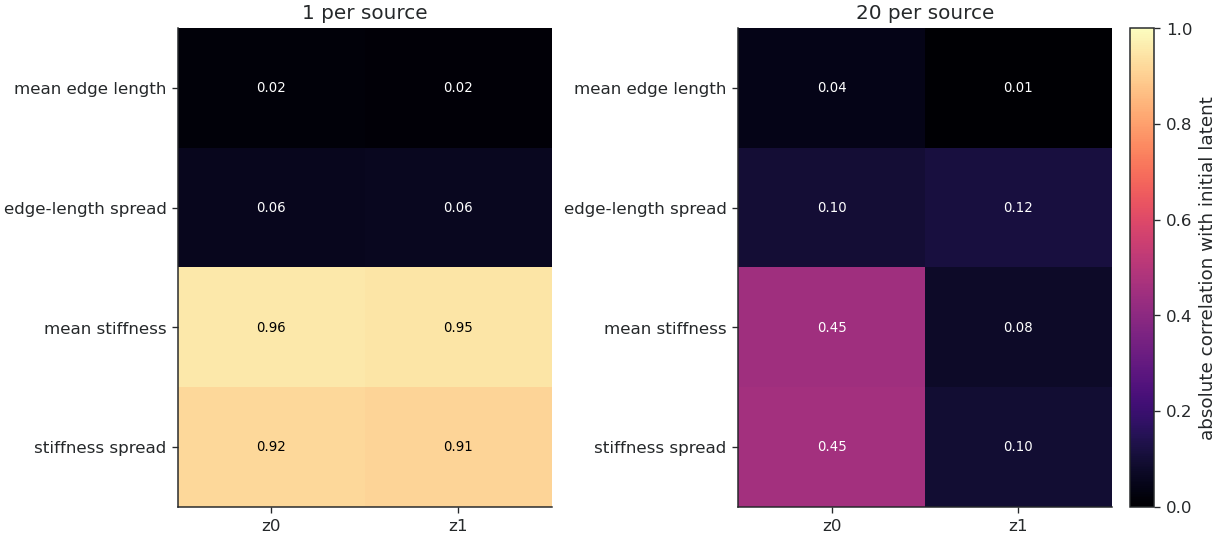

,training,descriptor,latent,absolute correlation,valid/total
0,1 per source,mean_edge_length,z0,0.016,80/80
1,1 per source,mean_edge_length,z1,0.015,80/80
2,1 per source,std_edge_length,z0,0.057,80/80
3,1 per source,std_edge_length,z1,0.061,80/80
4,1 per source,mean_stiffness,z0,0.957,80/80
5,1 per source,mean_stiffness,z1,0.949,80/80
6,1 per source,std_stiffness,z0,0.921,80/80
7,1 per source,std_stiffness,z1,0.913,80/80
8,20 per source,mean_edge_length,z0,0.044,80/80
9,20 per source,mean_edge_length,z1,0.007,80/80


All latent states, responses and reference descriptors use stiffness-optimized low-T trajectories.


In [4]:
STATIC=ROOT/'notebooks/results/initial_latent_origin_z/static_descriptors.csv'
if not STATIC.exists(): raise FileNotFoundError(STATIC)
static=pd.read_csv(STATIC).query("source=='stiffness_low'").copy()
candidate=['mean_edge_length','std_edge_length','mean_stiffness','std_stiffness']
descriptor_labels={'mean_edge_length':'mean edge length','std_edge_length':'edge-length spread','mean_stiffness':'mean stiffness','std_stiffness':'stiffness spread'}
initial=descriptors[['training','source','trajectory_id','initial z0','initial z1']].merge(static.drop(columns='final_p_ratio'),on=['source','trajectory_id'],validate='many_to_one')
static_rows=[]
for training,g in initial.groupby('training'):
    for feature in candidate:
        for latent in ['initial z0','initial z1']:
            static_rows.append({'training':training,'descriptor':feature,'latent':latent.replace('initial ',''),'absolute correlation':abs(g[latent].corr(g[feature])),'valid/total':'80/80'})
static_corr=pd.DataFrame(static_rows)
fig,axes=plt.subplots(1,2,figsize=(10.2,4.5),constrained_layout=True)
for ax,training in zip(axes,RUNS):
    table=static_corr.query('training==@training').pivot(index='descriptor',columns='latent',values='absolute correlation').loc[candidate]
    image=ax.imshow(table,vmin=0,vmax=1,cmap='magma',aspect='auto')
    ax.set(title=training,yticks=range(len(candidate)),yticklabels=[descriptor_labels[v] for v in candidate],xticks=[0,1],xticklabels=table.columns)
    for row in range(len(candidate)):
        for column in range(2): ax.text(column,row,f'{table.iloc[row,column]:.2f}',ha='center',va='center',fontsize=8,color='white' if table.iloc[row,column]<.72 else 'black')
fig.colorbar(image,ax=axes,label='absolute correlation with initial latent',fraction=.03,pad=.02)
plt.show()
display(static_corr.round(3))
print('All latent states, responses and reference descriptors use stiffness-optimized low-T trajectories.')


## Latent response


/tmp/ipykernel_3765266/85266405.py:45: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxes=ax.boxplot(groups,labels=labels,patch_artist=True,showfliers=False,medianprops={'color':PAPER_COLORS['ink'],'lw':1.4})
/tmp/ipykernel_3765266/85266405.py:45: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxes=ax.boxplot(groups,labels=labels,patch_artist=True,showfliers=False,medianprops={'color':PAPER_COLORS['ink'],'lw':1.4})


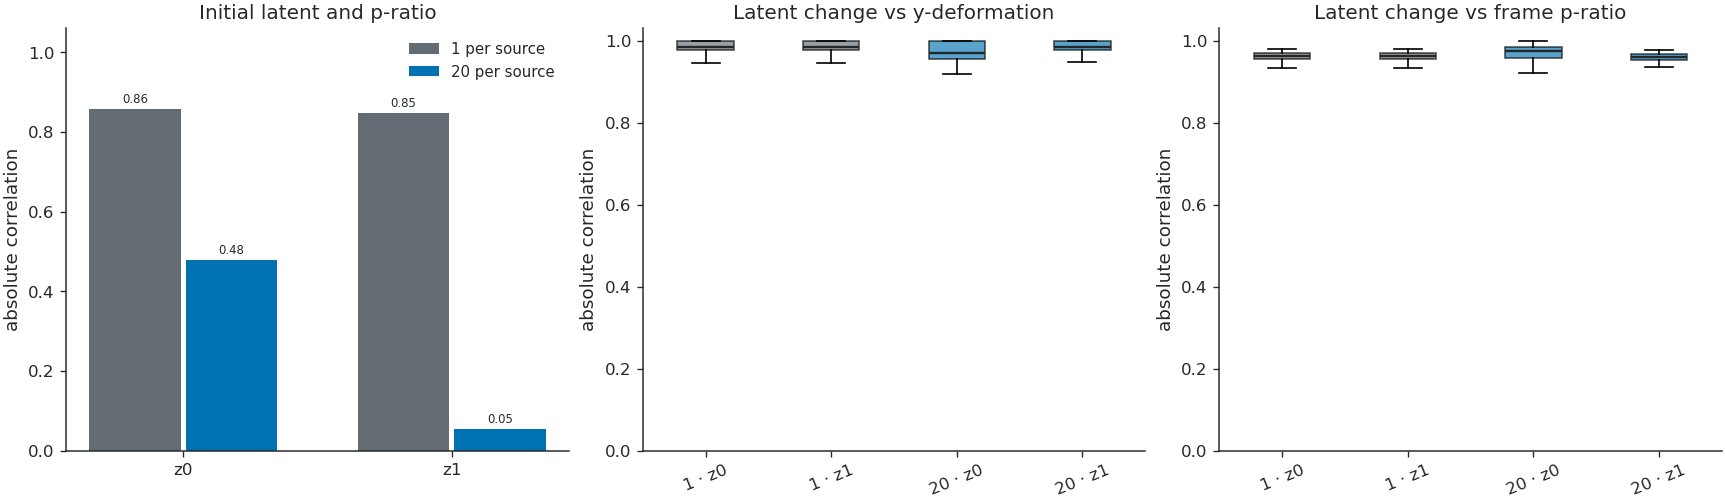

In [5]:
STATIC_FEATURES=['initial z0','initial z1']
global_rows=[]
for training,g in descriptors.query("source=='stiffness_low'").groupby('training'):
    for feature in STATIC_FEATURES:
        global_rows.append({
            'training':training,'descriptor':feature,
            '|Pearson r|':abs(g[feature].corr(g.final_p_ratio)),
        })
global_correlations=pd.DataFrame(global_rows)

within_rows=[]
for (training,ident),trajectory in frame_df.query(
    "source=='stiffness_low' and frame<=5"
).sort_values('frame').groupby(['training','trajectory_id']):
    trajectory=trajectory.copy()
    trajectory['z0 change']=trajectory.z0-trajectory.z0.iloc[0]
    trajectory['z1 change']=trajectory.z1-trajectory.z1.iloc[0]
    trajectory=trajectory.query('frame>0')
    for latent in ['z0','z1']:
        latent_change=trajectory[latent+' change']
        within_rows.extend([
            {'training':training,'trajectory_id':ident,'latent':latent,
             'comparison':'y-deformation','absolute correlation':abs(latent_change.corr(trajectory.y_deformation))},
            {'training':training,'trajectory_id':ident,'latent':latent,
             'comparison':'frame p-ratio','absolute correlation':abs(latent_change.corr(trajectory.p_ratio))},
        ])
within_correlations=pd.DataFrame(within_rows)

fig,axes=plt.subplots(1,3,figsize=(14.4,4.2),constrained_layout=True)
training_style={'1 per source':(PAPER_COLORS['slate'],-.18),'20 per source':(PAPER_COLORS['blue'],.18)}
x=np.arange(len(STATIC_FEATURES))
for training,(color,offset) in training_style.items():
    values=global_correlations.query('training==@training').set_index('descriptor').loc[STATIC_FEATURES,'|Pearson r|']
    bars=axes[0].bar(x+offset,values,width=.34,color=color,label=training)
    axes[0].bar_label(bars,fmt='%.2f',padding=2,fontsize=7)
axes[0].set(title='Initial latent and p-ratio',xticks=x,xticklabels=['z0','z1'],ylim=(0,1.06))
style_axes(axes[0],ylabel='absolute correlation',legend=True)

for ax,comparison in zip(axes[1:],['y-deformation','frame p-ratio']):
    groups=[]; labels=[]; colors=[]
    for training,color in [('1 per source',PAPER_COLORS['slate']),('20 per source',PAPER_COLORS['blue'])]:
        for latent in ['z0','z1']:
            groups.append(within_correlations.query('training==@training and latent==@latent and comparison==@comparison')['absolute correlation'].dropna())
            labels.append(f'{training.split()[0]} · {latent}'); colors.append(color)
    boxes=ax.boxplot(groups,labels=labels,patch_artist=True,showfliers=False,medianprops={'color':PAPER_COLORS['ink'],'lw':1.4})
    for patch,color in zip(boxes['boxes'],colors): patch.set_facecolor(color); patch.set_alpha(.65)
    ax.set(title=f'Latent change vs {comparison}',ylim=(0,1.03))
    ax.tick_params(axis='x',rotation=22)
    style_axes(ax,ylabel='absolute correlation')
plt.show()


## Low-T edge importance


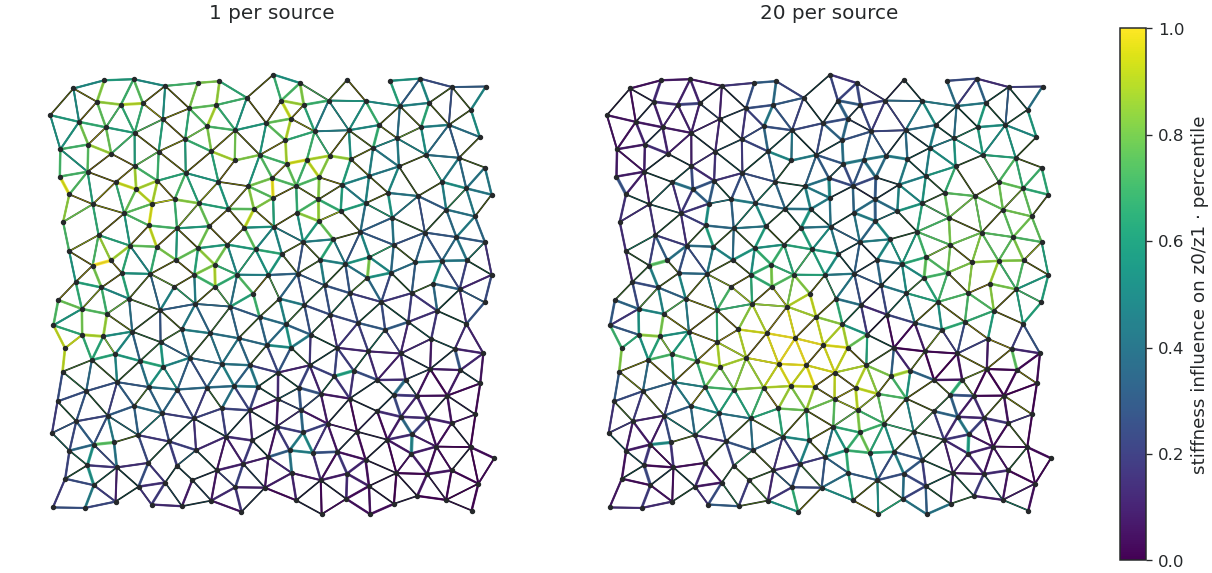

In [6]:
EDGE_DIR=ROOT/'notebooks/results/edge_attribution_one_vs_twenty'
required=[EDGE_DIR/'edge_influence.csv',EDGE_DIR/'metadata.json']
missing=[str(p) for p in required if not p.exists()]
if missing: raise FileNotFoundError('Missing low-T attribution artifacts:\n'+'\n'.join(missing))
edge_importance=pd.read_csv(required[0]).query("source=='stiffness_low'")
edge_metadata=json.loads(required[1].read_text())
ATTRIBUTION_RUNS=['1 per source','20 per source']

def attribution_graph(training):
    table=edge_importance.query('training==@training').copy()
    graph=nx.Graph()
    for edge in table.itertuples():
        graph.add_node(int(edge.node_i),pos=(float(edge.x_i),float(edge.y_i)))
        graph.add_node(int(edge.node_j),pos=(float(edge.x_j),float(edge.y_j)))
        graph.add_edge(int(edge.node_i),int(edge.node_j))
    width,height=edge_metadata['drawing_box_by_source']['stiffness_low'].values()
    graph.graph['box']={'x1':0.0,'x2':width,'y1':0.0,'y2':height}
    visible=remove_periodic_edges(graph)
    visible_keys={tuple(sorted(edge)) for edge in visible.edges}
    keep=[tuple(sorted((int(row.node_i),int(row.node_j)))) in visible_keys for row in table.itertuples()]
    return graph,table.loc[keep].copy()

fig,axes=plt.subplots(1,2,figsize=(10.2,4.8),constrained_layout=True)
for ax,training in zip(axes,ATTRIBUTION_RUNS):
    network,graph=attribution_graph(training)
    graph['influence percentile']=graph.stiffness_influence.rank(pct=True,method='average')
    stiffness=(graph.stiffness-graph.stiffness.min())/(graph.stiffness.max()-graph.stiffness.min()+1e-12)
    graph['width']=.25+1.8*stiffness
    graph=graph.sort_values('influence percentile')
    draw_graph(network,periodic_edges=False,node_color=PAPER_COLORS['ink'],node_size=5,
               show_labels=False,ax=ax,show=False)
    nx.draw_networkx_edges(
        remove_periodic_edges(network),nx.get_node_attributes(network,'pos'),
        edgelist=list(zip(graph.node_i.astype(int),graph.node_j.astype(int))),
        edge_color=graph['influence percentile'].to_numpy(),edge_cmap=plt.cm.viridis,
        edge_vmin=0,edge_vmax=1,width=graph.width.to_numpy(),alpha=.88,ax=ax,
    )
    ax.set_title(training); ax.set_aspect('equal'); ax.set_axis_off()
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0,1),cmap='viridis'),ax=axes,
             label='stiffness influence on z0/z1 · percentile',fraction=.025,pad=.02)
plt.show()


## Early response


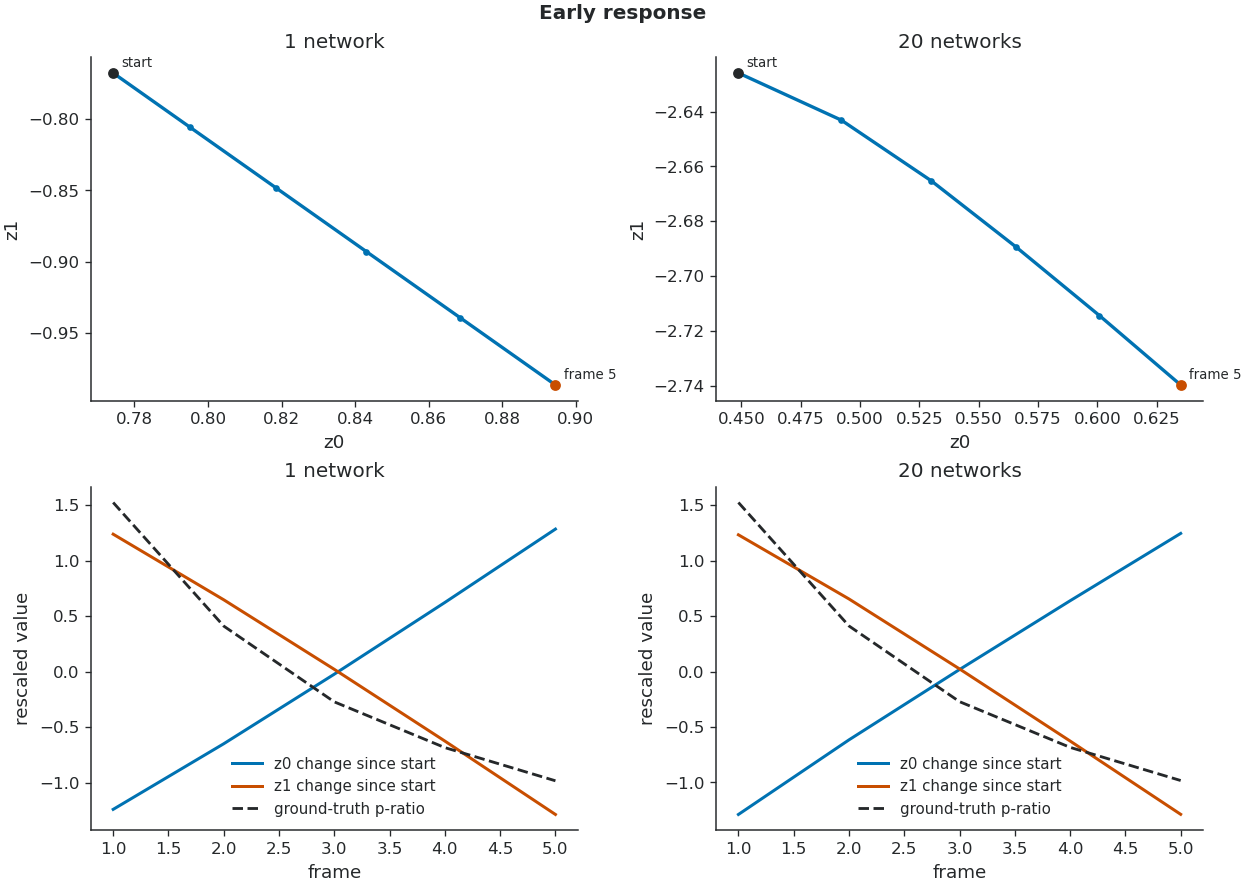

In [7]:
MATCHED_ID=40
matched={}
for training in RUNS:
    matched[training]=(frame_df.query(
        "training==@training and source=='stiffness_low' and trajectory_id==@MATCHED_ID"
    ).sort_values('frame').reset_index(drop=True))
for column in ['x_deformation','y_deformation','p_ratio']:
    np.testing.assert_allclose(
        matched['1 per source'][column].to_numpy(),
        matched['20 per source'][column].to_numpy(),
        equal_nan=True,
    )

def scaled(values):
    return (values-values.mean())/values.std()

fig,axes=plt.subplots(2,2,figsize=(10.4,7.4),constrained_layout=True)
for column,training in enumerate(RUNS):
    trajectory=matched[training].query('frame<=5').copy()
    count='1 network' if training=='1 per source' else '20 networks'

    ax=axes[0,column]
    ax.plot(trajectory.z0,trajectory.z1,color=PAPER_COLORS['blue'],lw=2,marker='o',ms=3)
    ax.scatter(trajectory.loc[0,'z0'],trajectory.loc[0,'z1'],color=PAPER_COLORS['ink'],s=30,zorder=3)
    ax.scatter(trajectory.loc[5,'z0'],trajectory.loc[5,'z1'],color=PAPER_COLORS['red'],s=30,zorder=3)
    ax.annotate('start',(trajectory.loc[0,'z0'],trajectory.loc[0,'z1']),xytext=(5,4),textcoords='offset points',fontsize=8)
    ax.annotate('frame 5',(trajectory.loc[5,'z0'],trajectory.loc[5,'z1']),xytext=(5,4),textcoords='offset points',fontsize=8)
    ax.set_title(count)
    style_axes(ax,xlabel='z0',ylabel='z1')

    steps=trajectory.query('frame>0').copy()
    steps['z0 change']=steps.z0-trajectory.z0.iloc[0]
    steps['z1 change']=steps.z1-trajectory.z1.iloc[0]

    ax=axes[1,column]
    ax.plot(steps.frame,scaled(steps['z0 change']),color=PAPER_COLORS['blue'],lw=1.8,label='z0 change since start')
    ax.plot(steps.frame,scaled(steps['z1 change']),color=PAPER_COLORS['red'],lw=1.8,label='z1 change since start')
    ax.plot(steps.frame,scaled(steps.p_ratio),color=PAPER_COLORS['ink'],lw=1.7,ls='--',label='ground-truth p-ratio')
    ax.set_title(count)
    style_axes(ax,xlabel='frame',ylabel='rescaled value',legend=True)

fig.suptitle('Early response',fontweight='semibold')
plt.show()


## Interpretation

The encoder receives each low-T graph frame's node displacements together with its static reference positions, edge geometry, connectivity and spring stiffnesses. It never receives optimization label or p-ratio.

With one trajectory per source, z0 and z1 mostly encode the dominant structure-conditioned deformation direction. With twenty trajectories, the encoder must also organize variation among unseen stiffness patterns and their framewise responses, so the two coordinates become less redundant and the early path can bend.

The initial coordinates describe the network's static mechanical identity; movement through latent space describes its observed deformation. Low-T data make that distinction visible without the mixed-temperature fluctuations dominating it.
